# Minimal MNIST Flow Matching + Memorization Tracking

Smoke-test notebook: train a small UNet via flow matching on N MNIST images,
snapshot every k steps, and compute f_mem at each snapshot to watch the
memorization curve emerge.

In [23]:
import sys, os

sys.path.insert(0, os.path.abspath(".."))

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms

from experiments.natural_images.common.utils import seed_everything
from experiments.natural_images.common.flow_matching import FlowMatching
from experiments.natural_images.common.networks.unet import SmallUNet
from experiments.natural_images.common.training.ema import EMA
from experiments.natural_images.common.evaluation.memorization import (
    compute_nn_stats,
    compute_f_mem,
)

%matplotlib inline

In [ ]:
# ---- Knobs ----
N = 4  # training set size (small = memorization regime)
PRED_SPACE = "eps"  # prediction parameterization: "x", "eps", or "v"
LOSS_SPACE = "eps"  # loss space
TOTAL_STEPS = 10000  # total optimizer steps
SNAPSHOT_EVERY = TOTAL_STEPS // 20  # compute f_mem every k steps
N_GEN = 200  # samples to generate per snapshot
SAMPLE_STEPS = 50  # ODE steps (heun) per snapshot (cheap for smoke test)
BATCH_SIZE = 4
LR = 2e-4
EMA_DECAY = 0.999  # faster EMA for short runs
SEED = 42
DEVICE = (
    "mps"
    if torch.backends.mps.is_available()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)

print(f"Device: {DEVICE}")

Device: mps


## 1. Load MNIST subset and freeze the training tensor

Training tensor: torch.Size([4, 1, 32, 32]), range [-1.00, 0.99]


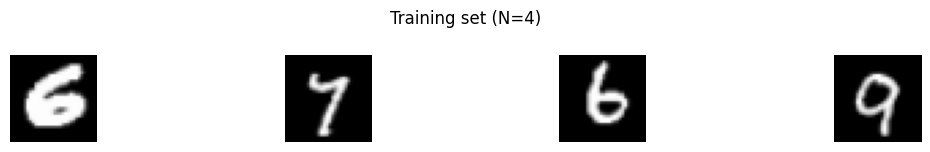

In [25]:
seed_everything(SEED)

# Download MNIST, resize to 32x32, scale to [-1, 1]
tf = transforms.Compose(
    [
        transforms.Resize(32),
        transforms.ToTensor(),  # [0, 1]
        transforms.Normalize([0.5], [0.5]),  # [-1, 1]
    ]
)
full_mnist = datasets.MNIST(root="../tmp/data", train=True, download=True, transform=tf)

# Deterministic subsample of N images
perm = torch.randperm(len(full_mnist))[:N]
train_imgs = torch.stack([full_mnist[i][0] for i in perm])  # (N, 1, 32, 32)
train_dataset = TensorDataset(train_imgs)

print(
    f"Training tensor: {train_imgs.shape}, range [{train_imgs.min():.2f}, {train_imgs.max():.2f}]"
)

# Quick look at a few samples
fig, axes = plt.subplots(1, 4, figsize=(12, 1.5))
for i, ax in enumerate(axes):
    ax.imshow(train_imgs[i, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
    ax.axis("off")
fig.suptitle(f"Training set (N={N})")
plt.tight_layout()

## 2. Build model: SmallUNet + FlowMatching wrapper

In [26]:
# Small UNet for 32x32 greyscale — use base_channels=32 to keep it light
network = SmallUNet(
    in_channels=1,
    base_channels=32,
    channel_mults=(1, 4),
    attention_resolutions=(8,),
    num_res_blocks=2,
    dropout=0.0,
)
flow_model = FlowMatching(network, pred_space=PRED_SPACE, loss_space=LOSS_SPACE).to(
    DEVICE
)

n_params = sum(p.numel() for p in flow_model.parameters())
print(f"Model params: {n_params / 1e6:.2f}M  |  pred={PRED_SPACE}, loss={LOSS_SPACE}")

Model params: 3.17M  |  pred=v, loss=v


## 3. Training loop with periodic snapshots

Every `SNAPSHOT_EVERY` steps: generate samples with EMA weights, compute f_mem.

In [27]:
# import tqdm  functionality
from tqdm import tqdm

In [28]:
# Optimizer and EMA
optimizer = torch.optim.AdamW(flow_model.parameters(), lr=LR, weight_decay=1e-4)
ema = EMA(flow_model, decay=EMA_DECAY)

# Data loader
loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

# Tracking
loss_log = []
snapshot_log = []  # list of {"step": int, "f_mem": float, "mean_r": float}

loader_iter = iter(loader)
flow_model.train()

pbar = tqdm(range(1, TOTAL_STEPS + 1), desc="Training", ncols=100)
for step in pbar:
    # Cycle through data
    try:
        (batch,) = next(loader_iter)
    except StopIteration:
        loader_iter = iter(loader)
        (batch,) = next(loader_iter)

    batch = batch.to(DEVICE)
    optimizer.zero_grad()
    loss = flow_model.compute_loss(batch)
    loss.backward()
    optimizer.step()
    ema.update()

    loss_log.append(loss.item())
    pbar.set_postfix(loss=f"{loss.item():.4f}")

    # ---- Snapshot ----
    if step % SNAPSHOT_EVERY == 0 or step == TOTAL_STEPS:
        ema.apply()
        flow_model.eval()
        with torch.no_grad():
            print("Sampling...")
            samples = flow_model.sample(
                shape=(N_GEN, 1, 32, 32),
                n_steps=SAMPLE_STEPS,
                method="heun",
                device=DEVICE,
            ).cpu()
            print(f"Generated {len(samples)} samples")
        flow_model.train()
        ema.restore()

        nn_stats = compute_nn_stats(samples, train_imgs)
        f_mem = compute_f_mem(nn_stats["r"], threshold=0.5)
        mean_r = nn_stats["r"].mean().item()

        snapshot_log.append({"step": step, "f_mem": f_mem, "mean_r": mean_r})
        pbar.set_postfix(
            loss=f"{loss.item():.4f}",
            f_mem=f"{f_mem:.3f}",
            mean_r=f"{mean_r:.3f}",
        )

print("Done.")

Training:   5%|█▊                                  | 498/10000 [00:17<05:24, 29.28it/s, loss=0.1075]

Sampling...


Training:   5%|█▋                                | 502/10000 [00:40<5:03:57,  1.92s/it, loss=0.0966]

Generated 200 samples


Training:  10%|███▌                                | 997/10000 [00:57<05:24, 27.73it/s, loss=0.0660]

Sampling...


... (70 outputs left out)

Training: 100%|██████████████████████████████████▉| 9998/10000 [13:59<00:00, 29.04it/s, loss=0.0045]

Sampling...


Training: 100%|███████| 10000/10000 [14:22<00:00, 11.60it/s, f_mem=1.000, loss=0.0045, mean_r=0.082]

Generated 200 samples
Done.


## 4. Results

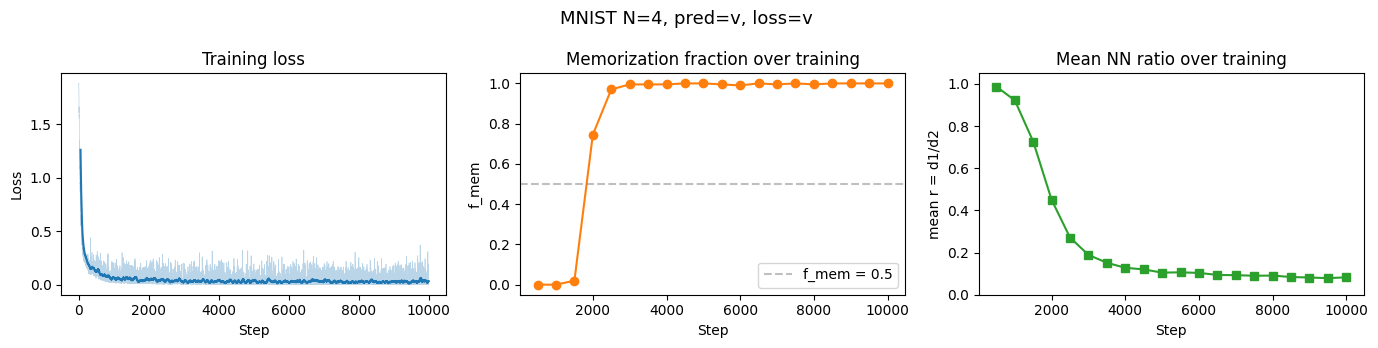

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

# (a) Loss curve
axes[0].plot(loss_log, alpha=0.3, linewidth=0.5)
# smoothed
window = min(50, len(loss_log) // 4)
if window > 1:
    smooth = np.convolve(loss_log, np.ones(window) / window, mode="valid")
    axes[0].plot(range(window - 1, len(loss_log)), smooth, color="C0", linewidth=1.5)
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training loss")

# (b) f_mem over training
steps = [s["step"] for s in snapshot_log]
fmems = [s["f_mem"] for s in snapshot_log]
axes[1].plot(steps, fmems, "o-", color="C1")
axes[1].axhline(0.5, ls="--", color="gray", alpha=0.5, label="f_mem = 0.5")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("f_mem")
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_title("Memorization fraction over training")
axes[1].legend()

# (c) mean r over training
mean_rs = [s["mean_r"] for s in snapshot_log]
axes[2].plot(steps, mean_rs, "s-", color="C2")
axes[2].set_xlabel("Step")
axes[2].set_ylabel("mean r = d1/d2")
axes[2].set_ylim(0, 1.05)
axes[2].set_title("Mean NN ratio over training")

fig.suptitle(f"MNIST N={N}, pred={PRED_SPACE}, loss={LOSS_SPACE}", fontsize=13)
plt.tight_layout()
plt.show()

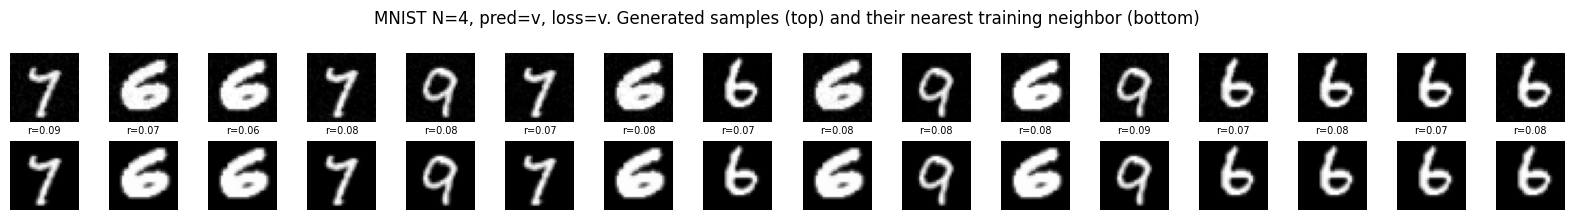

In [ ]:
# Show generated samples from the final snapshot alongside their nearest training neighbors
ema.apply()
flow_model.eval()
with torch.no_grad():
    final_samples = flow_model.sample(
        shape=(16, 1, 32, 32), n_steps=SAMPLE_STEPS, method="heun", device=DEVICE
    ).cpu()
ema.restore()

final_nn = compute_nn_stats(final_samples, train_imgs)

fig, axes = plt.subplots(2, 16, figsize=(16, 2.2))
for i in range(16):
    axes[0, i].imshow(final_samples[i, 0], cmap="gray", vmin=-1, vmax=1)
    axes[0, i].axis("off")
    nn_idx = final_nn["nn_idx"][i].item()
    axes[1, i].imshow(train_imgs[nn_idx, 0], cmap="gray", vmin=-1, vmax=1)
    axes[1, i].axis("off")
    axes[1, i].set_title(f"r={final_nn['r'][i]:.2f}", fontsize=7)

axes[0, 0].set_ylabel("Gen", fontsize=9)
axes[1, 0].set_ylabel("NN", fontsize=9)
fig.suptitle(
    f"MNIST N={N}, pred={PRED_SPACE}, loss={LOSS_SPACE}. Generated samples (top) and their nearest training neighbor (bottom)"
)
plt.tight_layout()
plt.show()

In [39]:
# Summary table
import pandas as pd

df = pd.DataFrame(snapshot_log)
df

,step,f_mem,mean_r
0,500,0.000,0.986897
1,1000,0.000,0.922074
2,1500,0.020,0.726305
3,2000,0.745,0.449633
4,2500,0.970,0.270845
5,3000,0.995,0.188753
6,3500,0.995,0.151554
7,4000,0.995,0.127741
8,4500,1.000,0.120109
9,5000,1.000,0.104745
